# Pronóstico del IMACEC con modelos ARIMA: revisión en Python

El informe original de este repositorio (`report/IMACEC_REPORT.docx`) aplica la metodología Box-Jenkins en Gretl y elige un modelo ARIMA(0,1,12) sobre el logaritmo del IMACEC. Este notebook reproduce el análisis en Python con `statsmodels` y corrige cuatro puntos de método:

1. **Fecha de corte explícita.** El informe menciona un "conjunto de prueba" sin decir qué meses lo forman. Aquí los últimos 24 meses se reservan para prueba y no se usan para estimar ni para elegir el modelo.
2. **AIC comparables.** El informe compara AIC de modelos estimados en niveles y en logaritmos, y sobre muestras de distinto largo. Aquí el AIC solo se compara entre modelos con la misma transformación, la misma muestra y el mismo orden de diferenciación.
3. **Modelo base.** Se agrega un pronóstico ingenuo estacional (repetir el valor del mismo mes del año anterior) como piso.
4. **Errores en puntos del índice.** Las métricas se calculan sobre el IMACEC en su escala original (índice 2018 = 100), no sobre el logaritmo.

Al final se evalúa si el modelo elegido en el informe se sostiene.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

FIGURES_DIR = Path("../figures")
pd.set_option("display.width", 160)

## 1. Datos

`data/IMACEC.xlsx` es la planilla que publica el Banco Central de Chile. Se usa la hoja `original_niveles`, columna "Total Imacec": la serie original (sin desestacionalizar), mensual, como índice con base promedio 2018 = 100.

In [2]:
raw = pd.read_excel("../data/IMACEC.xlsx", sheet_name="original_niveles", header=None)

# Las filas mensuales empiezan después de los promedios anuales: la primera es enero de 2018.
first_row = raw.index[(raw[0] == 2018) & (raw[1] == "ene")][0]
monthly = raw.loc[first_row:, [1, 10]].dropna()
monthly = monthly[monthly[1].isin(["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])]

imacec = pd.Series(
    monthly[10].astype(float).to_numpy(),
    index=pd.date_range("2018-01-01", periods=len(monthly), freq="MS"),
    name="IMACEC",
)

print(f"Observaciones: {len(imacec)} ({imacec.index[0]:%Y-%m} a {imacec.index[-1]:%Y-%m})")
print(f"Media: {imacec.mean():.2f}   Desviación estándar: {imacec.std():.2f}   Mínimo: {imacec.min():.2f}   Máximo: {imacec.max():.2f}")

Observaciones: 91 (2018-01 a 2025-07)
Media: 104.36   Desviación estándar: 7.98   Mínimo: 85.00   Máximo: 126.26


La serie tiene 91 observaciones mensuales, de enero de 2018 a julio de 2025, con media 104,36. Coincide con el Anexo 1 del informe (91 observaciones válidas, media 104,36), así que es la misma serie. El texto del informe habla de "enero de 2018 a julio de 2022", pero los datos llegan hasta julio de 2025.

## 2. Partición temporal

En series de tiempo la partición debe respetar el orden: se entrena con el pasado y se prueba con el futuro.

- **Entrenamiento:** enero de 2018 a julio de 2023 (67 meses).
- **Prueba:** agosto de 2023 a julio de 2025 (24 meses, dos ciclos estacionales completos).

La fecha de corte es el **31 de julio de 2023**. Todo lo que sigue (pruebas de estacionariedad, identificación y elección del modelo) usa solo el tramo de entrenamiento.

Entrenamiento: 67 meses (2018-01 a 2023-07)
Prueba:        24 meses (2023-08 a 2025-07)


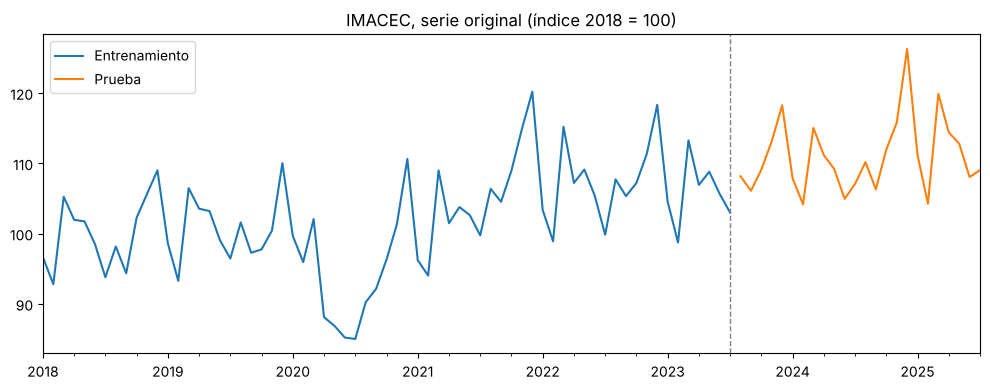

In [3]:
CUTOFF = "2023-07-01"
HORIZON = 24

train = imacec[:CUTOFF]
test = imacec[CUTOFF:].iloc[1:]
log_train = np.log(train)

assert len(test) == HORIZON
print(f"Entrenamiento: {len(train)} meses ({train.index[0]:%Y-%m} a {train.index[-1]:%Y-%m})")
print(f"Prueba:        {len(test)} meses ({test.index[0]:%Y-%m} a {test.index[-1]:%Y-%m})")

fig, ax = plt.subplots(figsize=(10, 4))
train.plot(ax=ax, label="Entrenamiento")
test.plot(ax=ax, label="Prueba")
ax.axvline(pd.Timestamp(CUTOFF), color="gray", linestyle="--", linewidth=1)
ax.set_title("IMACEC, serie original (índice 2018 = 100)")
ax.set_xlabel("")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Estacionariedad

Se trabaja con el logaritmo de la serie para estabilizar la varianza, igual que en el informe. La prueba de Dickey-Fuller aumentada (ADF) tiene como hipótesis nula que la serie tiene raíz unitaria (no es estacionaria).

In [4]:
def adf_p_value(series):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        return adfuller(series.dropna(), autolag="AIC")[1]


transformations = {
    "log(IMACEC)": log_train,
    "Primera diferencia": log_train.diff(),
    "Diferencia estacional (12 meses)": log_train.diff(12),
    "Primera diferencia + diferencia estacional": log_train.diff().diff(12),
}

adf_table = pd.DataFrame(
    {
        "Observaciones": {name: int(series.dropna().shape[0]) for name, series in transformations.items()},
        "p-valor ADF": {name: round(adf_p_value(series), 4) for name, series in transformations.items()},
    }
)
adf_table

,Observaciones,p-valor ADF
log(IMACEC),67,0.7644
Primera diferencia,66,0.4937
Diferencia estacional (12 meses),55,0.1051
Primera diferencia + diferencia estacional,54,0.0000


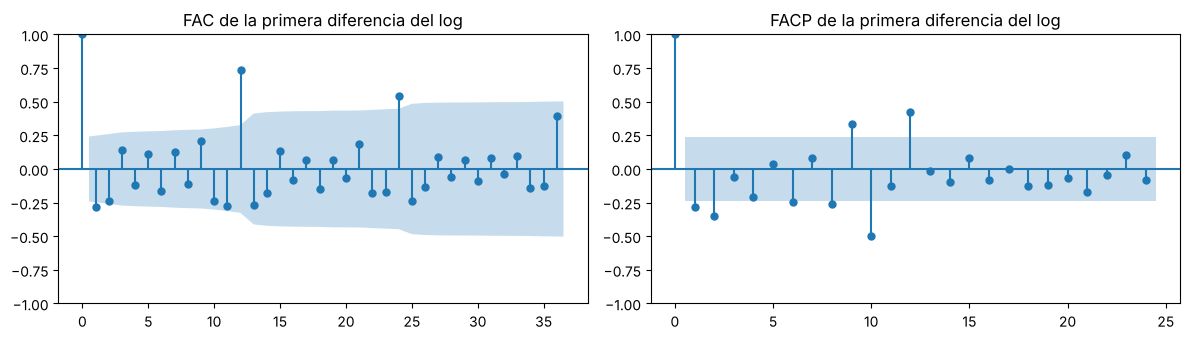

In [5]:
differenced = log_train.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(differenced, lags=36, ax=axes[0], title="FAC de la primera diferencia del log")
plot_pacf(differenced, lags=24, ax=axes[1], title="FACP de la primera diferencia del log", method="ywm")
fig.tight_layout()
plt.show()

**Lectura.**

- El logaritmo de la serie no es estacionario (p = 0,76).
- **La primera diferencia sola tampoco lo es en esta muestra** (p = 0,49). El informe concluye que la serie es I(1) y que una diferencia basta; con el tramo de entrenamiento usado aquí esa conclusión no se reproduce.
- La razón está en el correlograma: la autocorrelación de la primera diferencia es 0,74 en el rezago 12 y sigue alta en el 24 (0,54) y el 36 (0,39), muy por encima de la banda de significancia (0,24). Ese decaimiento lento en los múltiplos de 12 es la huella de una estacionalidad anual fuerte que la primera diferencia no elimina.
- Con la primera diferencia más la diferencia estacional la serie sí es estacionaria (p < 0,001).

Esto apunta a modelos con diferencia estacional (SARIMA), que el informe no considera.

## 4. Modelos candidatos y comparación por AIC

Se estiman dos familias de modelos, todas sobre el **logaritmo** de la serie y sobre el **mismo tramo de entrenamiento**:

- **Familia A, sin diferencia estacional (d = 1, D = 0).** Son los modelos del informe: ARIMA(1,1,1), ARIMA(0,1,12) y ARIMA(1,1,12). Como en el informe, el "12" indica un único término de media móvil en el rezago 12, y se incluye una constante (deriva).
- **Familia B, con diferencia estacional (d = 1, D = 1).** Modelos SARIMA, que tratan la estacionalidad diferenciando contra el mismo mes del año anterior.

El AIC solo es comparable entre modelos que explican los mismos datos. Al diferenciar se pierden observaciones (1 en la familia A, 13 en la B), así que **el AIC se compara dentro de cada familia y no entre familias**. Para comparar entre familias se usa el error de pronóstico (sección 5).

In [6]:
MA_12 = [0] * 11 + [1]  # solo el rezago 12

CANDIDATES = {
    "ARIMA(1,1,1)": {"order": (1, 1, 1), "seasonal_order": (0, 0, 0, 0), "trend": "t", "familia": "A"},
    "ARIMA(0,1,12) [informe]": {"order": (0, 1, MA_12), "seasonal_order": (0, 0, 0, 0), "trend": "t", "familia": "A"},
    "ARIMA(1,1,12)": {"order": (1, 1, MA_12), "seasonal_order": (0, 0, 0, 0), "trend": "t", "familia": "A"},
    "SARIMA(0,1,1)(0,1,1)12": {"order": (0, 1, 1), "seasonal_order": (0, 1, 1, 12), "trend": None, "familia": "B"},
    "SARIMA(1,1,0)(0,1,1)12": {"order": (1, 1, 0), "seasonal_order": (0, 1, 1, 12), "trend": None, "familia": "B"},
    "SARIMA(1,1,1)(0,1,1)12": {"order": (1, 1, 1), "seasonal_order": (0, 1, 1, 12), "trend": None, "familia": "B"},
    "SARIMA(0,1,1)(1,1,0)12": {"order": (0, 1, 1), "seasonal_order": (1, 1, 0, 12), "trend": None, "familia": "B"},
}


def fit_model(log_series, spec):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        warnings.simplefilter("ignore", UserWarning)
        model = ARIMA(log_series, order=spec["order"], seasonal_order=spec["seasonal_order"], trend=spec["trend"])
        return model.fit()


def forecast_levels(result, steps):
    # Se vuelve a la escala original con la exponencial (pronóstico de la mediana).
    return np.exp(result.forecast(steps))


fits = {name: fit_model(log_train, spec) for name, spec in CANDIDATES.items()}

rows = []
for name, result in fits.items():
    residuals = result.resid.iloc[result.loglikelihood_burn:]
    ma_roots = np.abs(result.maroots) if len(result.maroots) else np.array([np.inf])
    rows.append(
        {
            "Modelo": name,
            "Familia": CANDIDATES[name]["familia"],
            "Obs. efectivas": int(result.nobs_effective),
            "Parámetros": len(result.params),
            "AIC": round(result.aic, 2),
            "Ljung-Box p (rezago 12)": round(acorr_ljungbox(residuals, lags=[12])["lb_pvalue"].iloc[0], 3),
            "Menor módulo de raíz MA": round(float(ma_roots.min()), 3),
        }
    )

aic_table = pd.DataFrame(rows).set_index("Modelo")
aic_table

,Familia,Obs. efectivas,Parámetros,AIC,Ljung-Box p (rezago 12),Menor módulo de raíz MA
Modelo,,,,,,
"ARIMA(1,1,1)",A,66,4,-176.36,0.000,1.000
"ARIMA(0,1,12) [informe]",A,66,3,-200.37,0.003,1.019
"ARIMA(1,1,12)",A,66,4,-198.80,0.007,1.025
"SARIMA(0,1,1)(0,1,1)12",B,54,3,-227.34,0.330,1.024
"SARIMA(1,1,0)(0,1,1)12",B,54,3,-226.15,0.226,1.015
"SARIMA(1,1,1)(0,1,1)12",B,54,4,-226.74,0.506,1.014
"SARIMA(0,1,1)(1,1,0)12",B,54,3,-221.45,0.714,2.183


**Lectura.**

- Dentro de la **familia A**, el modelo del informe, ARIMA(0,1,12), tiene el menor AIC (−200,37 frente a −198,80 y −176,36). Comparado de forma correcta contra sus pares, la elección del informe dentro de esa familia se mantiene.
- Sin embargo, **los residuos de los tres modelos de la familia A están autocorrelacionados** (Ljung-Box p < 0,01): no capturan toda la estructura de la serie. El informe reporta que su modelo pasaba esta prueba sobre una muestra más corta (48 meses); con 66 meses no la pasa.
- En la **familia B** todos los modelos pasan la prueba de Ljung-Box (p > 0,2). Los tres con media móvil estacional tienen AIC muy parecidos (entre −227,34 y −226,15), una diferencia demasiado pequeña para decidir entre ellos solo con este criterio.
- Los AIC de la familia B son menores, pero **no se pueden comparar con los de la familia A**: se calculan sobre 54 observaciones efectivas y no sobre 66.

## 5. Elección del modelo con validación de origen móvil

Para comparar modelos de familias distintas, y contra el modelo base, se mide lo que importa: el error de pronóstico fuera de muestra. Para no usar el conjunto de prueba en la elección, la validación se hace **dentro del entrenamiento**:

- Se fijan 5 orígenes de pronóstico (julio de 2021 a julio de 2022, cada 3 meses).
- En cada origen se estima el modelo con los datos disponibles hasta esa fecha y se pronostican los 12 meses siguientes.
- Se promedia el error absoluto medio (MAE) en puntos del índice.

**Modelo base:** pronóstico ingenuo estacional, que repite para cada mes el valor del mismo mes del año anterior.

In [7]:
def seasonal_naive(history, steps):
    last_year = history.iloc[-12:].to_numpy()
    return np.resize(last_year, steps)


ORIGINS = pd.date_range("2021-07-01", "2022-07-01", freq="3MS")
VALIDATION_HORIZON = 12

validation_errors = {name: [] for name in ["Ingenuo estacional", *CANDIDATES]}
for origin in ORIGINS:
    history = train[:origin]
    actual = train[origin:].iloc[1 : VALIDATION_HORIZON + 1]
    assert len(actual) == VALIDATION_HORIZON

    validation_errors["Ingenuo estacional"].append(np.abs(actual.to_numpy() - seasonal_naive(history, VALIDATION_HORIZON)).mean())
    for name, spec in CANDIDATES.items():
        forecast = forecast_levels(fit_model(np.log(history), spec), VALIDATION_HORIZON)
        validation_errors[name].append(np.abs(actual.to_numpy() - forecast.to_numpy()).mean())

validation_table = pd.DataFrame(validation_errors, index=[f"{origin:%Y-%m}" for origin in ORIGINS]).T
validation_table["MAE promedio"] = validation_table.mean(axis=1)
validation_table = validation_table.round(2).sort_values("MAE promedio")
validation_table.index.name = "Modelo"
validation_table.columns.name = "Origen del pronóstico"

SELECTED = validation_table.drop(index="Ingenuo estacional").index[0]
print(f"Modelo con menor MAE promedio en validación: {SELECTED}")
validation_table

Modelo con menor MAE promedio en validación: SARIMA(1,1,0)(0,1,1)12


Origen del pronóstico,2021-07,2021-10,2022-01,2022-04,2022-07,MAE promedio
Modelo,,,,,,
"SARIMA(1,1,0)(0,1,1)12",1.95,2.63,2.61,3.03,1.31,2.30
"SARIMA(1,1,1)(0,1,1)12",2.07,2.82,2.21,3.25,1.45,2.36
"SARIMA(0,1,1)(0,1,1)12",2.87,3.27,2.24,3.62,1.33,2.67
Ingenuo estacional,8.04,4.93,2.96,1.76,1.38,3.81
"SARIMA(0,1,1)(1,1,0)12",3.29,5.39,2.99,7.07,2.18,4.18
"ARIMA(1,1,1)",9.83,6.70,5.28,4.21,4.58,6.12
"ARIMA(1,1,12)",8.38,10.65,9.53,4.04,12.94,9.11
"ARIMA(0,1,12) [informe]",8.91,11.25,9.20,12.11,13.75,11.04


**Lectura.**

- El mejor modelo en validación es **SARIMA(1,1,0)(0,1,1)12**, con un MAE promedio de 2,30 puntos del índice, frente a 3,81 del pronóstico ingenuo estacional. Los otros dos SARIMA con media móvil estacional quedan muy cerca (2,36 y 2,67).
- **El modelo del informe es el peor de todos**: 11,04 puntos de error promedio, casi el triple que el modelo base.
- El modelo base no es un rival débil: en los dos orígenes más recientes (2022-04 y 2022-07) iguala o supera al modelo elegido. Su mal promedio viene de los orígenes de 2021, cuando el año anterior estaba distorsionado por la pandemia.
- Son solo 5 orígenes, y sus ventanas de validación se solapan. Las diferencias pequeñas entre modelos SARIMA no son concluyentes; la diferencia con la familia A sí lo es.

## 6. Evaluación en el conjunto de prueba

Con el modelo ya elegido, se estima cada modelo con todo el entrenamiento (hasta julio de 2023) y se pronostican de una vez los 24 meses de prueba. Las métricas están en puntos del índice (MAE y RMSE) y en porcentaje del valor observado (MAPE). Se muestran todos los modelos para dar contexto, pero la elección se hizo en la sección anterior, sin mirar estos resultados.

In [8]:
def forecast_metrics(actual, forecast):
    errors = actual.to_numpy() - np.asarray(forecast)
    return {
        "MAE (puntos)": np.abs(errors).mean(),
        "RMSE (puntos)": np.sqrt((errors**2).mean()),
        "MAPE (%)": (np.abs(errors) / actual.to_numpy()).mean() * 100,
        "MAE meses 1-12": np.abs(errors[:12]).mean(),
        "MAE meses 13-24": np.abs(errors[12:]).mean(),
    }


test_forecasts = {"Ingenuo estacional": pd.Series(seasonal_naive(train, HORIZON), index=test.index)}
for name, result in fits.items():
    forecast = forecast_levels(result, HORIZON)
    forecast.index = test.index
    test_forecasts[name] = forecast

test_table = pd.DataFrame({name: forecast_metrics(test, forecast) for name, forecast in test_forecasts.items()}).T
test_table = test_table.round(2).sort_values("MAE (puntos)")
test_table.index.name = "Modelo"
test_table

,MAE (puntos),RMSE (puntos),MAPE (%),MAE meses 1-12,MAE meses 13-24
Modelo,,,,,
"SARIMA(1,1,0)(0,1,1)12",2.14,2.51,1.93,2.33,1.95
"SARIMA(1,1,1)(0,1,1)12",2.27,2.64,2.05,2.45,2.08
"SARIMA(0,1,1)(0,1,1)12",2.37,2.78,2.14,2.49,2.26
"SARIMA(0,1,1)(1,1,0)12",2.99,3.52,2.71,2.92,3.06
Ingenuo estacional,3.50,4.24,3.13,2.07,4.93
"ARIMA(1,1,1)",4.03,5.44,3.53,3.43,4.64
"ARIMA(1,1,12)",6.06,7.49,5.54,4.18,7.95
"ARIMA(0,1,12) [informe]",7.47,9.10,6.84,5.05,9.90


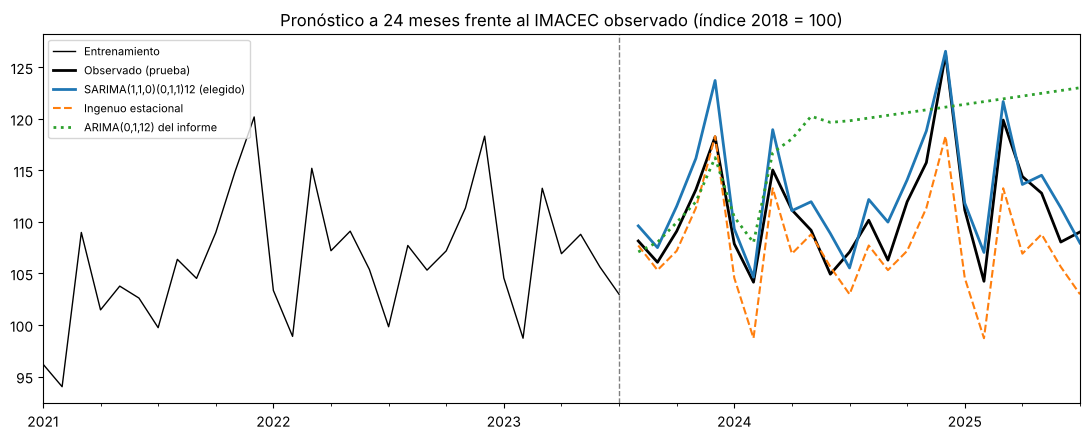

In [9]:
REPORT_MODEL = "ARIMA(0,1,12) [informe]"

fig, ax = plt.subplots(figsize=(11, 4.5))
train["2021-01":].plot(ax=ax, color="black", linewidth=1, label="Entrenamiento")
test.plot(ax=ax, color="black", linewidth=2, label="Observado (prueba)")
test_forecasts[SELECTED].plot(ax=ax, linewidth=2, label=f"{SELECTED} (elegido)")
test_forecasts["Ingenuo estacional"].plot(ax=ax, linestyle="--", label="Ingenuo estacional")
test_forecasts[REPORT_MODEL].plot(ax=ax, linestyle=":", linewidth=2, label="ARIMA(0,1,12) del informe")
ax.axvline(pd.Timestamp(CUTOFF), color="gray", linestyle="--", linewidth=1)
ax.set_title("Pronóstico a 24 meses frente al IMACEC observado (índice 2018 = 100)")
ax.set_xlabel("")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pronostico_prueba_python.png", dpi=150)
plt.show()

**Lectura.**

- El modelo elegido, **SARIMA(1,1,0)(0,1,1)12, tiene un MAE de 2,14 puntos del índice** (MAPE 1,93 %) en los 24 meses de prueba. El pronóstico ingenuo estacional tiene 3,50 puntos (MAPE 3,13 %): el modelo reduce el error en un 39 %.
- **La ventaja no es uniforme.** En los primeros 12 meses el modelo base es algo mejor (2,07 frente a 2,33 puntos). El modelo gana en los meses 13 a 24 (1,95 frente a 4,93), porque el ingenuo repite el nivel del último año conocido y no incorpora el crecimiento de la economía.
- **El modelo del informe, ARIMA(0,1,12), tiene un MAE de 7,47 puntos** (MAPE 6,84 %), más del doble que el modelo base. El gráfico muestra por qué: un término de media móvil en el rezago 12 solo "recuerda" 12 meses, así que el pronóstico reproduce el patrón estacional durante el primer año y después se convierte en una recta con pendiente, sin estacionalidad.
- El modelo elegido en validación resultó también el mejor en prueba, lo que da algo de confianza en el procedimiento, aunque con una sola ventana de prueba no es una garantía.

## 7. ¿Se sostiene el modelo del informe?

El informe elige ARIMA(0,1,12) sobre el logaritmo, estimado con datos de 2018 a enero de 2022, y reporta MAPE 0,71, MAE 0,033 y RMSE 0,043 "en el set de prueba". Para entender esas cifras se reestima ese mismo modelo sobre esa misma muestra.

In [10]:
report_sample = np.log(imacec[:"2022-01"])
report_fit = fit_model(report_sample, CANDIDATES[REPORT_MODEL])

innovations_sd = float(np.sqrt(report_fit.params["sigma2"]))
print(f"Muestra: {report_sample.index[0]:%Y-%m} a {report_sample.index[-1]:%Y-%m} ({len(report_sample)} meses)")
print(f"AIC: {report_fit.aic:.2f}   (informe: -139,89)")
print(f"Coeficiente MA(12): {report_fit.params['ma.L12']:.4f}   (informe: 0,999999)")
print(f"Desviación estándar de las innovaciones, en logaritmos: {innovations_sd:.4f}   (RMSE del informe: 0,043)")
print(f"MAE del informe / media del logaritmo de la serie: {0.033 / report_sample.mean() * 100:.2f} %   (MAPE del informe: 0,71)")

Muestra: 2018-01 a 2022-01 (49 meses)
AIC: -139.89   (informe: -139,89)
Coeficiente MA(12): 0.9751   (informe: 0,999999)
Desviación estándar de las innovaciones, en logaritmos: 0.0438   (RMSE del informe: 0,043)
MAE del informe / media del logaritmo de la serie: 0.72 %   (MAPE del informe: 0,71)


**Lectura.**

- El modelo se reproduce: el AIC coincide con el del informe (−139,89).
- **El coeficiente MA(12) está en el límite de invertibilidad.** Gretl lo estimó en 0,999999; aquí, con la restricción de invertibilidad activa, queda en 0,975. Un coeficiente pegado a 1 indica que el modelo intenta imitar con un término de media móvil lo que en realidad es una raíz unitaria estacional, es decir, que falta la diferencia estacional.
- **Las métricas del informe no son errores de pronóstico en puntos del índice.** El RMSE reportado (0,043) coincide con la desviación estándar de las innovaciones del modelo en logaritmos (0,044). Y el MAPE reportado (0,71) es lo que resulta de dividir el MAE reportado (0,033) por el nivel medio del logaritmo de la serie (0,72 %). Las cifras son consistentes con errores de ajuste dentro de la muestra medidos sobre el logaritmo, no con errores sobre un conjunto de prueba. Un error de 0,71 % sobre el logaritmo (que vale cerca de 4,6) no equivale a un error de 0,71 % sobre el índice.

## 8. Conclusiones

1. **El modelo del informe no se sostiene como modelo de pronóstico.** ARIMA(0,1,12) tiene el mejor AIC entre los modelos sin diferencia estacional, pero sus residuos quedan autocorrelacionados, su coeficiente está en el límite de invertibilidad y, fuera de muestra, su error (7,47 puntos de MAE a 24 meses) es más del doble que el de repetir el valor del año anterior (3,50).
2. **La causa es la estacionalidad.** La serie original del IMACEC necesita una diferencia estacional además de la primera diferencia. El informe concluye que basta una diferencia y no considera modelos SARIMA.
3. **El modelo recomendado es SARIMA(1,1,0)(0,1,1)12** sobre el logaritmo: MAE de 2,14 puntos del índice (MAPE 1,93 %) en 24 meses de prueba, un 39 % menos que el modelo base. Se eligió con validación de origen móvil dentro del entrenamiento, sin usar la prueba.
4. **Las métricas del informe (MAPE 0,71) no son comparables con las de este notebook**: son consistentes con errores dentro de muestra en escala logarítmica.

### Limitaciones

- La muestra es corta (67 meses de entrenamiento) e incluye la pandemia de 2020, un quiebre que ningún modelo ARIMA univariado representa bien. No se modeló con variables de intervención.
- La evaluación final usa una sola ventana de prueba de 24 meses, y la validación solo 5 orígenes. Las diferencias entre modelos SARIMA parecidos no son concluyentes.
- En los primeros 12 meses de prueba el modelo elegido no supera al pronóstico ingenuo estacional.
- El IMACEC se publica con cifras preliminares que el Banco Central revisa; aquí se usa una sola versión de los datos.
- Al volver del logaritmo con la exponencial se obtiene un pronóstico de la mediana, levemente inferior a la media; el efecto es pequeño frente a los errores observados.